# Pirate Treasure Hunt — Initial Team Prototype (Group 7)
**Team:** Hanbin Lee, Valerie Stapleton, Famela Dauz  
**Purpose:** Shareable first implementation for review and collaborative development.

**Proposed game rules (prototype):** A single pirate moves on a static four-direction grid. `#` denotes impassable water, `C` a coin, `M` a map, and `T` the treasure. The pirate begins with **BFS**, switches to **Greedy Best-First Search** after collecting a coin, and switches permanently to **A\*** after collecting the map. Search restarts at the current location whenever an item changes the algorithm.

This is a *working prototype*, not the final game. The grid layout, item placement, and tie-breaking behavior are illustrative and can be changed by the team. Search algorithms are independently implemented in this notebook (standard textbook algorithms), with AIMA course notebooks as conceptual references.

In [1]:
from collections import deque
from heapq import heappush, heappop
from itertools import count
from time import perf_counter
import matplotlib.pyplot as plt

GRID = [
    "S..C#.....",
    ".#..#.....",
    ".#.....M..",
    "...##..#..",
    "......#...",
    ".#..#.....",
    "....#.....",
    "..#.......",
    ".....#....",
    "...#.....T",
]
assert len(set(map(len, GRID))) == 1, 'Grid rows must have equal lengths'
assert sum(row.count('S') for row in GRID) == 1
assert sum(row.count('T') for row in GRID) == 1
HEIGHT, WIDTH = len(GRID), len(GRID[0])
START = next((r,c) for r,row in enumerate(GRID) for c,v in enumerate(row) if v=='S')
GOAL = next((r,c) for r,row in enumerate(GRID) for c,v in enumerate(row) if v=='T')
COINS = {(r,c) for r,row in enumerate(GRID) for c,v in enumerate(row) if v=='C'}
MAPS = {(r,c) for r,row in enumerate(GRID) for c,v in enumerate(row) if v=='M'}
WALLS = {(r,c) for r,row in enumerate(GRID) for c,v in enumerate(row) if v=='#'}
print('Grid:', HEIGHT, 'x', WIDTH, '| Start:', START, '| Treasure:', GOAL)
print('Coins:', sorted(COINS), '| Maps:', sorted(MAPS))

Grid: 10 x 10 | Start: (0, 0) | Treasure: (9, 9)
Coins: [(0, 3)] | Maps: [(2, 7)]


## 1. Search algorithms
All moves have cost 1. Manhattan distance is an admissible heuristic for this four-direction grid. Each algorithm returns its proposed path, the number of expanded nodes, and elapsed computation time.

In [2]:
def neighbors(position):
    r,c=position
    for dr,dc in ((-1,0),(0,1),(1,0),(0,-1)):
        nxt=(r+dr,c+dc)
        if 0 <= nxt[0] < HEIGHT and 0 <= nxt[1] < WIDTH and nxt not in WALLS:
            yield nxt

def heuristic(a,b):
    return abs(a[0]-b[0])+abs(a[1]-b[1])

def reconstruct(parent, end):
    path=[end]
    while parent[path[-1]] is not None:
        path.append(parent[path[-1]])
    return list(reversed(path))

def search(start, goal, algorithm='BFS'):
    if algorithm not in ('BFS','Greedy','A*','UCS'):
        raise ValueError('Unknown algorithm: '+algorithm)
    tick=perf_counter()
    expanded=0
    parent={start:None}
    if algorithm=='BFS':
        frontier=deque([start]); discovered={start}
        while frontier:
            current=frontier.popleft(); expanded+=1
            if current==goal:
                return {'path':reconstruct(parent,goal),'expanded':expanded,'seconds':perf_counter()-tick}
            for nxt in neighbors(current):
                if nxt not in discovered:
                    discovered.add(nxt); parent[nxt]=current; frontier.append(nxt)
    else:
        sequence=count()
        frontier=[]; best_g={start:0}; closed=set()
        def priority(node,g):
            return heuristic(node,goal) if algorithm=='Greedy' else (g if algorithm=='UCS' else g+heuristic(node,goal))
        heappush(frontier,(priority(start,0),next(sequence),start,0))
        while frontier:
            _,_,current,g=heappop(frontier)
            if current in closed or g != best_g[current]:
                continue
            closed.add(current); expanded+=1
            if current==goal:
                return {'path':reconstruct(parent,goal),'expanded':expanded,'seconds':perf_counter()-tick}
            for nxt in neighbors(current):
                ng=g+1
                if nxt not in closed and (nxt not in best_g or ng < best_g[nxt]):
                    best_g[nxt]=ng; parent[nxt]=current
                    heappush(frontier,(priority(nxt,ng),next(sequence),nxt,ng))
    raise ValueError('No route from '+str(start)+' to '+str(goal))

for algorithm in ('BFS','Greedy','A*','UCS'):
    result=search(START,GOAL,algorithm)
    print(f'{algorithm:7} | steps={len(result["path"])-1:2} | expanded={result["expanded"]:3} | time={result["seconds"]*1000:.3f} ms')

BFS     | steps=18 | expanded= 86 | time=0.118 ms
Greedy  | steps=18 | expanded= 19 | time=0.063 ms
A*      | steps=18 | expanded= 75 | time=0.143 ms
UCS     | steps=18 | expanded= 86 | time=0.193 ms


## 2. Automatic algorithm switching
The pirate follows a currently planned route. When it lands on a **new** coin or map, it switches algorithms and replans from that exact position. The map takes precedence and keeps A* active permanently. Previously collected items are not collected again.

**Important limitation:** An item must lie along the pirate's route to be collected. This first prototype does **not** force the pirate to visit all coins or the map before reaching treasure; the team can decide whether to add that rule.

In [3]:
def play_game():
    position=START; mode='BFS'; collected_coins=set(); has_map=False
    visited=[position]; switches=[]; planning=[]
    for step in range(HEIGHT*WIDTH*20):
        if position==GOAL:
            break
        plan=search(position,GOAL,mode)
        planning.append({'from':position,'algorithm':mode,'expanded':plan['expanded'],'planned_steps':len(plan['path'])-1})
        route=plan['path']
        if len(route)<2:
            raise RuntimeError('No next move')
        changed=False
        for next_position in route[1:]:
            position=next_position; visited.append(position)
            if position in MAPS and not has_map:
                has_map=True
                if mode!='A*':
                    switches.append((len(visited)-1,position,mode,'A*','map'))
                    mode='A*'; changed=True
            elif position in COINS and position not in collected_coins:
                collected_coins.add(position)
                if mode=='BFS':
                    switches.append((len(visited)-1,position,mode,'Greedy','coin'))
                    mode='Greedy'; changed=True
            if changed or position==GOAL:
                break
        if position==GOAL:
            break
        if not changed:
            raise RuntimeError('Route ended without reaching goal or switching')
    else:
        raise RuntimeError('Maximum steps exceeded')
    return {'visited':visited,'switches':switches,'planning':planning,
            'coins':collected_coins,'has_map':has_map,'final_mode':mode,
            'steps':len(visited)-1,'reached_treasure':position==GOAL}

result=play_game()
print('Reached treasure:',result['reached_treasure'])
print('Total movement steps:',result['steps'])
print('Final algorithm:',result['final_mode'])
print('Coins collected:',sorted(result['coins']),'| Map collected:',result['has_map'])
print('Algorithm switches:')
for step,position,old,new,item in result['switches']:
    print(f'  step {step}: {old} -> {new} at {position} ({item})')
print('Search plans:',len(result['planning']))

Reached treasure: True
Total movement steps: 18
Final algorithm: A*
Coins collected: [(0, 3)] | Map collected: True
Algorithm switches:
  step 3: BFS -> Greedy at (0, 3) (coin)
  step 9: Greedy -> A* at (2, 7) (map)
Search plans: 3


## 3. Visualize the grid and actual traveled route
The blue line shows the **actual sequence of moves**, not just the final planned route. The start, treasure, coin, and map positions are labeled.

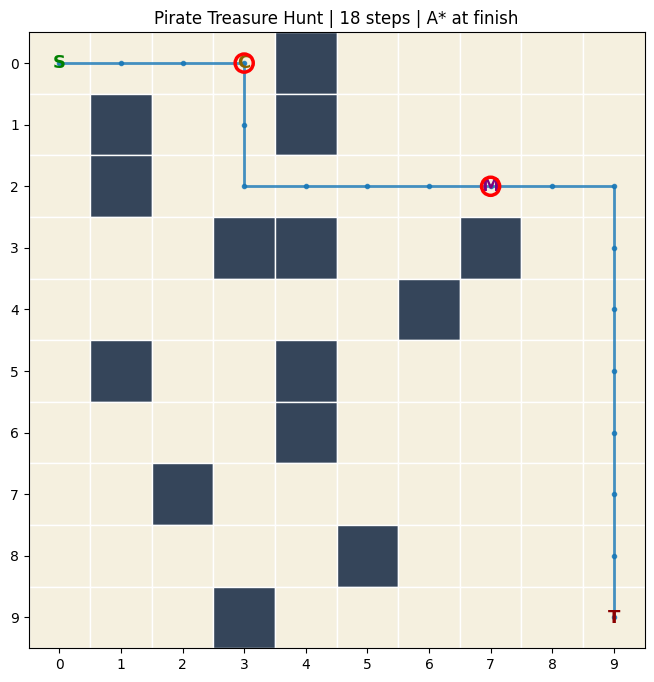

In [4]:
def draw_game(game_result):
    fig,ax=plt.subplots(figsize=(8,8))
    for r,row in enumerate(GRID):
        for c,symbol in enumerate(row):
            color='#35455a' if symbol=='#' else '#f5f0df'
            ax.add_patch(plt.Rectangle((c-.5,r-.5),1,1,facecolor=color,edgecolor='white'))
            if symbol in ('S','T','C','M'):
                ax.text(c,r,symbol,ha='center',va='center',fontsize=13,fontweight='bold',
                        color={'S':'green','T':'darkred','C':'#8a6200','M':'purple'}[symbol])
    path=game_result['visited']
    ax.plot([c for r,c in path],[r for r,c in path],'-o',color='#1677b8',lw=2,markersize=3,alpha=.8)
    for step,(r,c),old,new,item in game_result['switches']:
        ax.scatter([c],[r],s=170,facecolors='none',edgecolors='red',linewidths=2.5,zorder=5)
    ax.set_xlim(-.5,WIDTH-.5);ax.set_ylim(HEIGHT-.5,-.5)
    ax.set_xticks(range(WIDTH));ax.set_yticks(range(HEIGHT));ax.set_aspect('equal')
    ax.set_title(f'Pirate Treasure Hunt | {game_result["steps"]} steps | {game_result["final_mode"]} at finish')
    plt.show()

draw_game(result)

## 4. Baseline comparison on the same grid
Compare the same **start-to-treasure** search problem for BFS, UCS, Greedy, and A*. These are **planning** metrics, not full dynamic game-run metrics. The switching simulation is reported separately above. Time measurements vary between runs and machines.

In [5]:
baseline={name:search(START,GOAL,name) for name in ('BFS','UCS','Greedy','A*')}
print(f'{"Algorithm":<12}{"Steps":>8}{"Expanded":>12}{"Time (ms)":>14}')
for name,stats in baseline.items():
    print(f'{name:<12}{len(stats["path"])-1:>8}{stats["expanded"]:>12}{stats["seconds"]*1000:>14.3f}')
assert result['reached_treasure']
assert all(pos not in WALLS for pos in result['visited'])
assert all(heuristic(a,b)==1 for a,b in zip(result['visited'],result['visited'][1:]))
assert len(baseline['BFS']['path'])==len(baseline['UCS']['path'])==len(baseline['A*']['path'])
print('Sanity checks passed.')

Algorithm      Steps    Expanded     Time (ms)
BFS               18          86         0.110
UCS               18          86         0.151
Greedy            18          19         0.048
A*                18          75         0.207
Sanity checks passed.


## Suggested next steps for team discussion
1. Confirm the intended game rule: must the pirate collect a coin and map before the treasure, or are they optional pickups?
2. Decide whether to keep uniform movement costs or add terrain penalties. If terrain costs vary, UCS/A* comparison becomes more informative.
3. Add multiple maps, obstacles, and reproducible benchmark cases; collect metrics for the report.
4. Add a step-by-step animation or user-facing game controls if time permits.
5. Integrate with course-provided AIMA functions if the team prefers that structure, with appropriate attribution.

**Current status:** First runnable notebook with search, switching, visualization, and basic validation. Open for team review and edits.

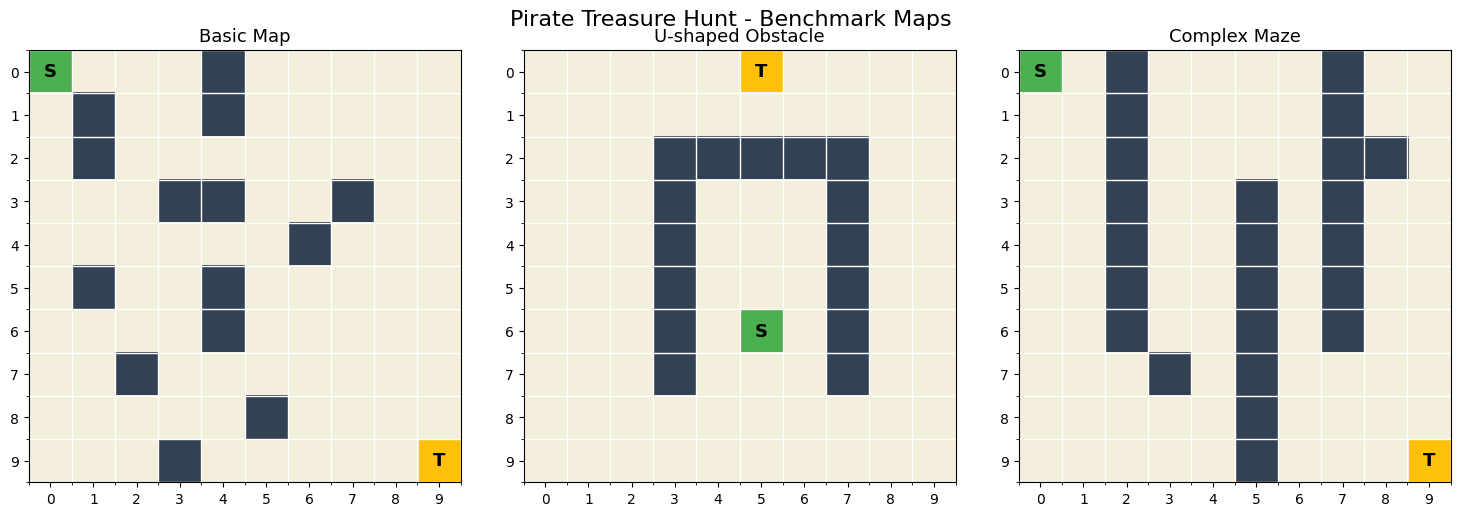

Total benchmark maps: 3


In [6]:

# 5. Additional Benchmark Maps

BENCHMARK_MAPS = {
    "Basic Map": {
        "start": START,
        "goal": GOAL,
        "walls": set(WALLS)
    },

    "U-shaped Obstacle": {
        "start": (6, 5),
        "goal": (0, 5),
        "walls": (
            {(r, 3) for r in range(2, 8)}
            | {(r, 7) for r in range(2, 8)}
            | {(2, c) for c in range(3, 8)}
        )
    },

    "Complex Maze": {
        "start": (0, 0),
        "goal": (9, 9),
        "walls": (
            {(r, 2) for r in range(7)}
            | {(r, 5) for r in range(3, 10)}
            | {(r, 7) for r in range(7)}
            | {(7, 3), (2, 8)}
        )
    }
}

# Visualize benchmark maps

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

cmap = ListedColormap([
    "#F4EFDC", "#334155", "#4CAF50", "#FFC107"
])

for ax, (name, config) in zip(axes, BENCHMARK_MAPS.items()):
    grid = np.zeros((10, 10))

    for r, c in config["walls"]:
        grid[r, c] = 1

    sr, sc = config["start"]
    gr, gc = config["goal"]

    grid[sr, sc] = 2
    grid[gr, gc] = 3

    ax.imshow(grid, cmap=cmap, vmin=0, vmax=3)
    ax.set_title(name, fontsize=13)
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    ax.set_xticks(np.arange(-0.5, 10, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 10, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1)

    ax.text(sc, sr, "S", ha="center", va="center",
            fontsize=13, fontweight="bold")
    ax.text(gc, gr, "T", ha="center", va="center",
            fontsize=13, fontweight="bold")

plt.suptitle("Pirate Treasure Hunt - Benchmark Maps",
             fontsize=16)
plt.tight_layout()
plt.show()

print("Total benchmark maps:", len(BENCHMARK_MAPS))


In [7]:

# 6. Enhanced Search Algorithms

from collections import deque
import heapq
import time
from itertools import count

def benchmark_search(config, algorithm):

    start = config["start"]
    goal = config["goal"]
    walls = config["walls"]

    timer = time.perf_counter()
    explored = set()
    expanded_nodes = []

    def h(pos):
        return abs(pos[0] - goal[0]) + abs(pos[1] - goal[1])

    def neighbors(pos):
        r, c = pos

        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            nr, nc = r + dr, c + dc

            if (0 <= nr < 10 and 0 <= nc < 10
                    and (nr, nc) not in walls):
                yield (nr, nc)

    def make_result(path):
        return {
            "path": path,
            "steps": len(path) - 1 if path else None,
            "cost": len(path) - 1 if path else None,
            "expanded": len(expanded_nodes),
            "expanded_nodes": expanded_nodes,
            "seconds": time.perf_counter() - timer,
            "success": bool(path)
        }

    if algorithm == "BFS":

        frontier = deque([(start, [start])])
        discovered = {start}

        while frontier:

            current, path = frontier.popleft()
            expanded_nodes.append(current)

            if current == goal:
                return make_result(path)

            for nxt in neighbors(current):
                if nxt not in discovered:
                    discovered.add(nxt)
                    frontier.append((nxt, path + [nxt]))

    elif algorithm in ("UCS", "Greedy", "A*"):

        frontier = []
        tie = count()

        heapq.heappush(
            frontier, (0, next(tie), 0, start, [start])
        )

        best_cost = {start: 0}

        while frontier:

            _, _, g, current, path = heapq.heappop(frontier)

            if current in explored:
                continue

            explored.add(current)
            expanded_nodes.append(current)

            if current == goal:
                return make_result(path)

            for nxt in neighbors(current):

                new_g = g + 1

                if nxt in explored:
                    continue

                if new_g >= best_cost.get(nxt, float("inf")):
                    continue

                best_cost[nxt] = new_g

                if algorithm == "UCS":
                    priority = new_g
                elif algorithm == "Greedy":
                    priority = h(nxt)
                else:
                    priority = new_g + h(nxt)

                heapq.heappush(
                    frontier,
                    (priority, next(tie), new_g,
                     nxt, path + [nxt])
                )

    else:
        raise ValueError("Unknown search algorithm")

    return make_result([])


# Run all algorithms on all benchmark maps

ALGORITHMS = ["BFS", "UCS", "Greedy", "A*"]
benchmark_results = {}

for map_name, config in BENCHMARK_MAPS.items():

    print("\n" + "=" * 65)
    print(map_name)
    print("=" * 65)

    print(f"{'Algorithm':<12}{'Steps':>8}"
          f"{'Cost':>8}{'Expanded':>12}"
          f"{'Time (ms)':>14}{'Success':>10}")

    for algorithm in ALGORITHMS:

        stats = benchmark_search(config, algorithm)
        benchmark_results[(map_name, algorithm)] = stats

        print(f"{algorithm:<12}"
              f"{str(stats['steps']):>8}"
              f"{str(stats['cost']):>8}"
              f"{stats['expanded']:>12}"
              f"{stats['seconds'] * 1000:>14.3f}"
              f"{str(stats['success']):>10}")

print("\nTotal benchmark cases:", len(benchmark_results))



Basic Map
Algorithm      Steps    Cost    Expanded     Time (ms)   Success
BFS               18      18          86         0.124      True
UCS               18      18          86         0.610      True
Greedy            20      20          21         0.108      True
A*                18      18          75         0.198      True

U-shaped Obstacle
Algorithm      Steps    Cost    Expanded     Time (ms)   Success
BFS               16      16          85         0.114      True
UCS               16      16          85         0.162      True
Greedy            16      16          37         0.085      True
A*                16      16          53         0.252      True

Complex Maze
Algorithm      Steps    Cost    Expanded     Time (ms)   Success
BFS               30      30          67         0.087      True
UCS               30      30          67         0.118      True
Greedy            32      32          43         0.106      True
A*                30      30          55      

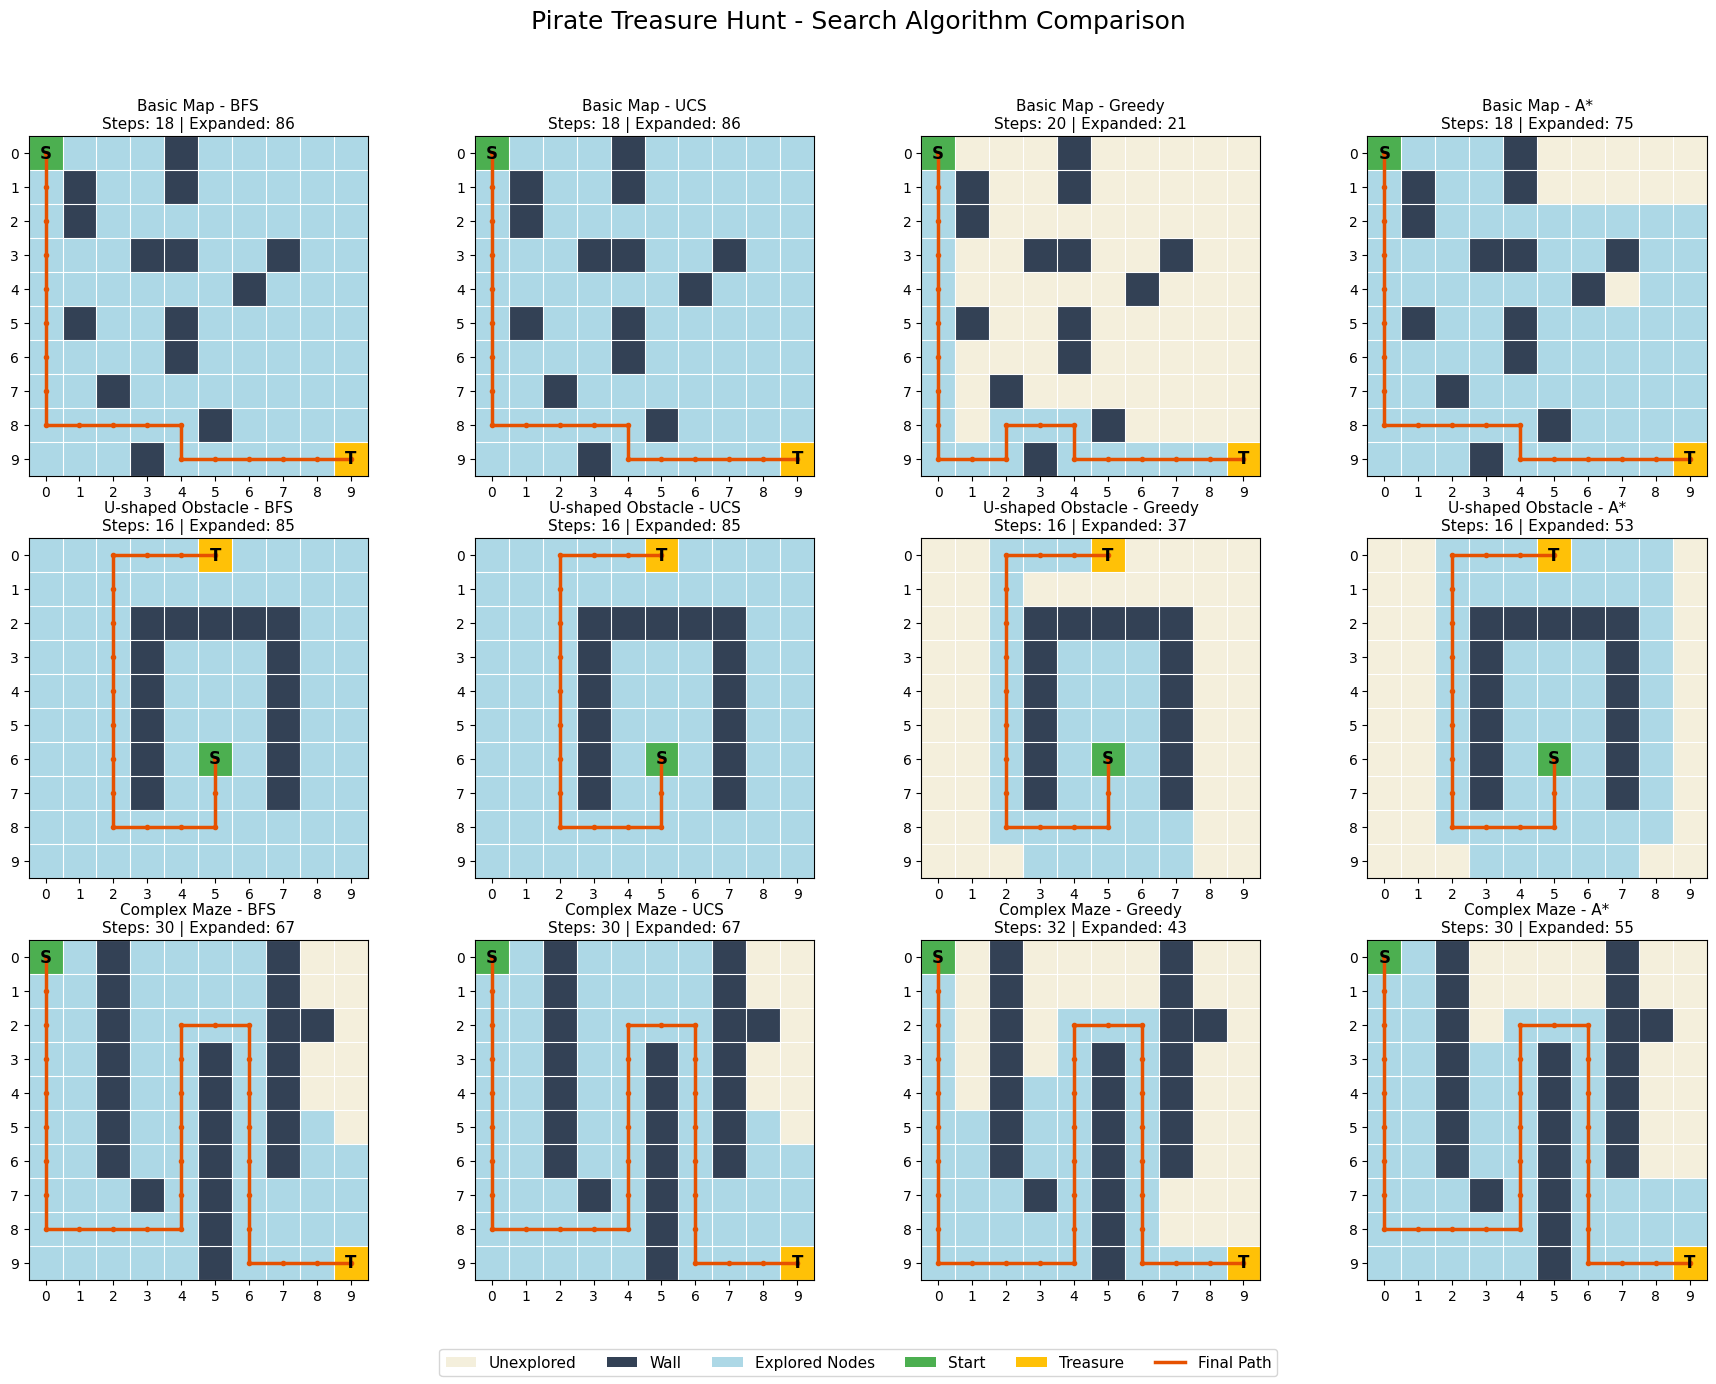

In [8]:

# 7. Visualization of Explored Nodes and Final Paths

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

fig, axes = plt.subplots(3, 4, figsize=(18, 14))

search_cmap = ListedColormap([
    "#F4EFDC",  # Unexplored
    "#334155",  # Wall
    "#ADD8E6",  # Explored
    "#4CAF50",  # Start
    "#FFC107"   # Treasure
])

for i, (map_name, config) in enumerate(BENCHMARK_MAPS.items()):

    for j, algorithm in enumerate(ALGORITHMS):

        ax = axes[i, j]
        stats = benchmark_results[(map_name, algorithm)]

        grid = np.zeros((10, 10))

        for r, c in config["walls"]:
            grid[r, c] = 1

        for r, c in stats["expanded_nodes"]:
            grid[r, c] = 2

        sr, sc = config["start"]
        gr, gc = config["goal"]

        grid[sr, sc] = 3
        grid[gr, gc] = 4

        ax.imshow(grid, cmap=search_cmap, vmin=0, vmax=4)

        if stats["path"]:
            rows, cols = zip(*stats["path"])

            ax.plot(cols, rows,
                    color="#E65100",
                    linewidth=2.5,
                    marker="o",
                    markersize=3)

        ax.text(sc, sr, "S", ha="center", va="center",
                fontsize=12, fontweight="bold")

        ax.text(gc, gr, "T", ha="center", va="center",
                fontsize=12, fontweight="bold")

        ax.set_title(
            f"{map_name} - {algorithm}\n"
            f"Steps: {stats['steps']} | "
            f"Expanded: {stats['expanded']}",
            fontsize=11
        )

        ax.set_xticks(range(10))
        ax.set_yticks(range(10))

        ax.set_xticks(np.arange(-0.5, 10, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, 10, 1), minor=True)

        ax.grid(which="minor", color="white", linewidth=0.8)
        ax.tick_params(which="minor", length=0)

legend_elements = [
    Patch(facecolor="#F4EFDC", label="Unexplored"),
    Patch(facecolor="#334155", label="Wall"),
    Patch(facecolor="#ADD8E6", label="Explored Nodes"),
    Patch(facecolor="#4CAF50", label="Start"),
    Patch(facecolor="#FFC107", label="Treasure"),
    Line2D([0], [0], color="#E65100",
           linewidth=2.5, label="Final Path")
]

fig.suptitle(
    "Pirate Treasure Hunt - Search Algorithm Comparison",
    fontsize=18
)

fig.legend(handles=legend_elements,
           loc="lower center", ncol=6, fontsize=11)

plt.tight_layout(rect=[0, 0.05, 1, 0.95])

plt.savefig("Pirate_Treasure_Hunt_Search_Comparison.png",
            dpi=200, bbox_inches="tight")

plt.show()


In [9]:

# 8. Adaptive Search Strategy

ITEM_LOCATIONS = {
    "Basic Map": {
        "coin": (3, 0),
        "map": (8, 4)
    },
    "U-shaped Obstacle": {
        "coin": (8, 5),
        "map": (4, 2)
    },
    "Complex Maze": {
        "coin": (5, 0),
        "map": (2, 4)
    }
}

def adaptive_search(config, items):

    current = config["start"]
    goal = config["goal"]

    algorithm = "BFS"
    collected = set()

    full_path = [current]
    all_expanded = []
    total_expanded = 0
    switches = []
    planning_time = 0
    planning_calls = 0

    while current != goal:

        local_config = {
            "start": current,
            "goal": goal,
            "walls": config["walls"]
        }

        stats = benchmark_search(local_config, algorithm)

        planning_calls += 1
        total_expanded += stats["expanded"]
        all_expanded.extend(stats["expanded_nodes"])
        planning_time += stats["seconds"]

        if not stats["success"]:
            break

        switched = False

        for nxt in stats["path"][1:]:

            current = nxt
            full_path.append(current)

            old_algorithm = algorithm

            if current == items["coin"] and "coin" not in collected:

                collected.add("coin")

                if algorithm == "BFS":
                    algorithm = "Greedy"

            if current == items["map"] and "map" not in collected:

                collected.add("map")
                algorithm = "A*"

            if old_algorithm != algorithm:

                switches.append({
                    "step": len(full_path) - 1,
                    "position": current,
                    "from": old_algorithm,
                    "to": algorithm
                })

                switched = True
                break

        if not switched:
            break

    return {
        "path": full_path,
        "steps": len(full_path) - 1,
        "cost": len(full_path) - 1,
        "expanded": total_expanded,
        "expanded_nodes": all_expanded,
        "unique_expanded": len(set(all_expanded)),
        "seconds": planning_time,
        "success": current == goal,
        "collected": collected,
        "switches": switches,
        "planning_calls": planning_calls,
        "final_algorithm": algorithm
    }


# Run adaptive search on all benchmark maps

adaptive_results = {}

for map_name, config in BENCHMARK_MAPS.items():

    stats = adaptive_search(
        config, ITEM_LOCATIONS[map_name]
    )

    adaptive_results[map_name] = stats
    benchmark_results[(map_name, "Adaptive")] = stats

    print("\n" + "=" * 55)
    print(map_name, "- Adaptive Search")
    print("=" * 55)

    print("Success:", stats["success"])
    print("Steps:", stats["steps"])
    print("Path Cost:", stats["cost"])
    print("Expanded Nodes:", stats["expanded"])
    print("Unique Expanded Nodes:", stats["unique_expanded"])
    print("Planning Calls:", stats["planning_calls"])
    print("Planning Time (ms):",
          round(stats["seconds"] * 1000, 3))
    print("Collected Items:", sorted(stats["collected"]))
    print("Final Algorithm:", stats["final_algorithm"])

    print("\nAlgorithm Switching History:")

    for event in stats["switches"]:

        print(
            f"Step {event['step']}: "
            f"{event['from']} -> {event['to']} "
            f"at {event['position']}"
        )

print("\nTotal benchmark cases:", len(benchmark_results))



Basic Map - Adaptive Search
Success: True
Steps: 20
Path Cost: 20
Expanded Nodes: 111
Unique Expanded Nodes: 86
Planning Calls: 3
Planning Time (ms): 0.211
Collected Items: ['coin', 'map']
Final Algorithm: A*

Algorithm Switching History:
Step 3: BFS -> Greedy at (3, 0)
Step 14: Greedy -> A* at (8, 4)

U-shaped Obstacle - Adaptive Search
Success: True
Steps: 16
Path Cost: 16
Expanded Nodes: 133
Unique Expanded Nodes: 85
Planning Calls: 3
Planning Time (ms): 0.222
Collected Items: ['coin', 'map']
Final Algorithm: A*

Algorithm Switching History:
Step 2: BFS -> Greedy at (8, 5)
Step 9: Greedy -> A* at (4, 2)

Complex Maze - Adaptive Search
Success: True
Steps: 32
Path Cost: 32
Expanded Nodes: 131
Unique Expanded Nodes: 67
Planning Calls: 3
Planning Time (ms): 0.243
Collected Items: ['coin', 'map']
Final Algorithm: A*

Algorithm Switching History:
Step 5: BFS -> Greedy at (5, 0)
Step 20: Greedy -> A* at (2, 4)

Total benchmark cases: 15


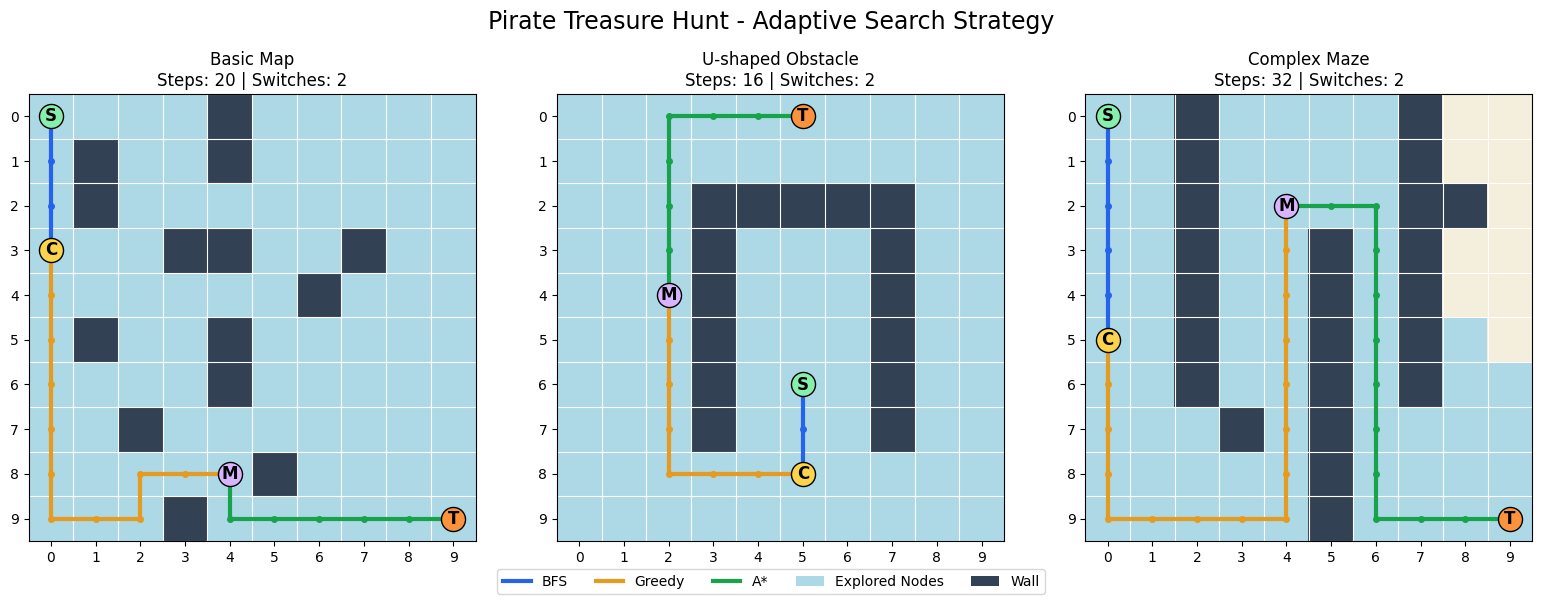

In [10]:

# 9. Visualization of Adaptive Search Strategy

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

algorithm_colors = {
    "BFS": "#2563EB",
    "Greedy": "#E59B20",
    "A*": "#16A34A"
}

adaptive_cmap = ListedColormap([
    "#F4EFDC",
    "#334155",
    "#ADD8E6"
])

for ax, (map_name, config) in zip(
        axes, BENCHMARK_MAPS.items()):

    stats = adaptive_results[map_name]
    items = ITEM_LOCATIONS[map_name]

    grid = np.zeros((10, 10))

    for r, c in config["walls"]:
        grid[r, c] = 1

    for r, c in stats["expanded_nodes"]:
        grid[r, c] = 2

    ax.imshow(grid, cmap=adaptive_cmap, vmin=0, vmax=2)

    path = stats["path"]
    boundaries = [0]
    stage_algorithms = ["BFS"]

    for event in stats["switches"]:
        boundaries.append(event["step"])
        stage_algorithms.append(event["to"])

    boundaries.append(len(path) - 1)

    # Draw each algorithm's path segment

    for i, algorithm in enumerate(stage_algorithms):

        segment = path[boundaries[i]:boundaries[i + 1] + 1]

        rows, cols = zip(*segment)

        ax.plot(
            cols, rows,
            color=algorithm_colors[algorithm],
            linewidth=3,
            marker="o",
            markersize=4,
            zorder=3
        )

    # Draw start, treasure, coin and map

    markers = [
        (config["start"], "S", "#86EFAC"),
        (items["coin"], "C", "#FCD34D"),
        (items["map"], "M", "#D8B4FE"),
        (config["goal"], "T", "#FB923C")
    ]

    for (r, c), label, color in markers:

        ax.scatter(c, r, s=300, color=color,
                   edgecolors="black", zorder=4)

        ax.text(c, r, label,
                ha="center", va="center",
                fontweight="bold", fontsize=12,
                zorder=5)

    ax.set_title(
        f"{map_name}\n"
        f"Steps: {stats['steps']} | "
        f"Switches: {len(stats['switches'])}",
        fontsize=12
    )

    ax.set_xticks(range(10))
    ax.set_yticks(range(10))

    ax.set_xticks(np.arange(-0.5, 10, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 10, 1), minor=True)

    ax.grid(which="minor", color="white", linewidth=0.8)
    ax.tick_params(which="minor", length=0)

legend_elements = [
    Line2D([0], [0], color=algorithm_colors["BFS"],
           lw=3, label="BFS"),
    Line2D([0], [0], color=algorithm_colors["Greedy"],
           lw=3, label="Greedy"),
    Line2D([0], [0], color=algorithm_colors["A*"],
           lw=3, label="A*"),
    Patch(facecolor="#ADD8E6", label="Explored Nodes"),
    Patch(facecolor="#334155", label="Wall")
]

fig.suptitle(
    "Pirate Treasure Hunt - Adaptive Search Strategy",
    fontsize=17
)

fig.legend(handles=legend_elements,
           loc="lower center", ncol=5)

plt.tight_layout(rect=[0, 0.07, 1, 0.93])

plt.savefig(
    "Pirate_Treasure_Hunt_Adaptive_Search.png",
    dpi=200, bbox_inches="tight"
)

plt.show()


In [11]:

# 10. Benchmark Summary and CSV Export

import pandas as pd

summary_rows = []

for (map_name, algorithm), stats in benchmark_results.items():

    summary_rows.append({
        "Map": map_name,
        "Algorithm": algorithm,
        "Steps": stats["steps"],
        "Path Cost": stats["cost"],
        "Expanded Nodes": stats["expanded"],
        "Unique Expanded Nodes": len(set(stats["expanded_nodes"])),
        "Planning Time (ms)": round(stats["seconds"] * 1000, 4),
        "Planning Calls": stats.get("planning_calls", 1),
        "Algorithm Switches": len(stats.get("switches", [])),
        "Success": stats["success"]
    })

benchmark_df = pd.DataFrame(summary_rows)

algorithm_order = ["BFS", "UCS", "Greedy", "A*", "Adaptive"]

benchmark_df["Algorithm"] = pd.Categorical(
    benchmark_df["Algorithm"],
    categories=algorithm_order,
    ordered=True
)

benchmark_df = benchmark_df.sort_values(
    ["Map", "Algorithm"]
).reset_index(drop=True)

display(benchmark_df)

benchmark_df.to_csv(
    "Pirate_Treasure_Hunt_Benchmark_Results.csv",
    index=False
)

print("Total benchmark cases:", len(benchmark_df))
print("Successful cases:", benchmark_df["Success"].sum())
print("CSV file exported successfully.")


,Map,Algorithm,Steps,Path Cost,Expanded Nodes,Unique Expanded Nodes,Planning Time (ms),Planning Calls,Algorithm Switches,Success
0,Basic Map,BFS,18,18,86,86,0.1240,1,0,True
1,Basic Map,UCS,18,18,86,86,0.6098,1,0,True
2,Basic Map,Greedy,20,20,21,21,0.1082,1,0,True
3,Basic Map,A*,18,18,75,75,0.1975,1,0,True
4,Basic Map,Adaptive,20,20,111,86,0.2110,3,2,True
5,Complex Maze,BFS,30,30,67,67,0.0869,1,0,True
6,Complex Maze,UCS,30,30,67,67,0.1176,1,0,True
7,Complex Maze,Greedy,32,32,43,43,0.1064,1,0,True
8,Complex Maze,A*,30,30,55,55,0.1306,1,0,True
9,Complex Maze,Adaptive,32,32,131,67,0.2435,3,2,True


Total benchmark cases: 15
Successful cases: 15
CSV file exported successfully.


## 11. Conclusion

### Benchmark Results

Five search strategies (BFS, UCS, Greedy Best-First Search, A*, and Adaptive Search) were evaluated across three benchmark maps: Basic Map, U-shaped Obstacle, and Complex Maze. All 15 benchmark cases successfully reached the treasure.

- **BFS and UCS:** Both algorithms consistently found optimal paths and produced identical results because movement costs were uniform.
- **Greedy Best-First Search:** Greedy expanded the fewest nodes across all three maps but produced longer paths in the Basic Map and Complex Maze.
- **A* Search:** A* consistently found optimal paths while expanding fewer nodes than BFS and UCS.
- **Adaptive Search:** The proposed strategy successfully switched from BFS to Greedy and then to A* upon collecting the coin and map items. However, repeated path planning resulted in additional node expansions.

### Overall Findings

The experimental results demonstrate a trade-off between path optimality, search efficiency, and adaptability. While A* provided a good balance between path optimality and search efficiency, Adaptive Search demonstrated the ability to dynamically change its search strategy based on in-game events.

### Limitations and Future Improvements

The current experiments are limited to three predefined maps with uniform movement costs and manually placed items. Planning times are based on single runs. Future improvements may include randomized maps, variable terrain costs, repeated runtime measurements, and further integration with the interactive Streamlit dashboard.